<center><h2><strong><font color="blue"> Advanced Programming for Data Science (APDS)</font></strong></h2></center>

<center><img alt="" src="images/covers/taudata-cover.jpg"/></center>

<center><h2><strong><font color="blue">APDS-07: Introduction to Pandas for Data Science</font></strong></h2></center>

<b><center><h3>(C) Taufik Sutanto</h3></center>
* .

In [ ]:
!pip install pandas seaborn numpy matplotlib --q

In [ ]:
# Importing Some Python Modules
import warnings; warnings.simplefilter('ignore')
import pandas as pd, numpy as np, seaborn as sns
import matplotlib.pyplot as plt
plt.style.use('bmh'); sns.set()
np.random.seed(420)

# <center><font color="blue"> Pandas DataFrame</font></center>

<center><img alt="" src="images/pandas_dataframe_structure.jpg" style="height: 350px;" /></center>

* A Pandas DataFrame can be constructed from a **Dictionary** or a **List/Tuple**

In [ ]:
# DataFrame from Dictionary
D = {'Name' : ['Ankit', 'Aishwarya', 'Shaurya', 'Shivangi'],
    'Age' : [23, 21, 22, 21],
    'University' : ['BHU', 'JNU', 'DU', 'BHU']} 
D

In [ ]:
df = pd.DataFrame(D)
df

In [ ]:
df.describe(include="all")

In [ ]:
df.Name

In [ ]:
D

In [ ]:
A = [1,2,3]
B = ["a", "b", "c"]

for x,y in zip(A,B):
    print(x,y)

In [ ]:
Name = ['Ankit', 'Aishwarya', 'Shaurya', 'Shivangi']
Age = [23, 21, 22, 21]

for student, age in zip(Name, Age):
    print(student, age)

In [ ]:
# DataFrame from List
Name = ['Ankit', 'Aishwarya', 'Shaurya', 'Shivangi']
Age = [23, 21, 22, 21]
University = ['BHU', 'JNU', 'DU', 'BHU'] 
df = pd.DataFrame(zip(Name, Age, University), columns=['Nama', 'Umur', 'Universitas'])
df

In [ ]:
df[:3]

In [ ]:
# Index slicing operates similarly to Lists, but caution is required.
print(df.index)
df[1:3] 

# <center><font color="blue"> OK, Let's Start!: Import-Loading Data</font></center>

<center><img alt="" src="images/meme-cartoon/Reading-and-Writing-Data-With-Pandas.jpg" style="height: 300px;" /></center>

# <center><font color="blue"> Case Study</font></center>

* Data Source: http://byebuyhome.com/
* Objective: To identify house prices that are below market value for investment purposes.
* Variables:
 - **Dist_Taxi** – distance to nearest taxi stand from the property
 - **Dist_Market** – distance to nearest grocery market from the property
 - **Dist_Hospital** – distance to nearest hospital from the property
 - **Carpet** – carpet area of the property in square feet
 - **Builtup** – built-up area of the property in square feet
 - **Parking** – type of car parking available with the property
 - **City_Category** – categorization of the city based on the size
 - **Rainfall** – annual rainfall in the area where property is located
 - **House_Price** – price at which the property was sold

<img alt="" src="images/property-investment-analysis.jpg" style="height: 250px;" />

# <center><font color="blue"> Import-Loading CSV / Excel Data via Pandas</font></center>

<img alt="" src="images/pandas load csv excel.png" style="height: 150px;" />

* Importing CSV file  https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html
* Importing Excel file  https://pandas.pydata.org/docs/reference/api/pandas.read_excel.html
* Encodings https://docs.python.org/3/library/codecs.html#standard-encodings

In [ ]:
file_ = 'data/price.csv'
try: # Running Locally, ensure "file_" is in the "data" folder
    price = pd.read_csv(file_)
except: # Running in Google Colab
    !mkdir data
    !wget -P data/ https://raw.githubusercontent.com/taudataanalytics/taudata-Academy/master/data/price.csv
    price = pd.read_csv(file_)
    
N, P = price.shape # Data Dimensions
print('rows = ', N, ', Columns (number of variables) = ', P)
print("Type of df Variable = ", type(price))


In [ ]:
price.sample(7)

# <center><font color="blue"> What about Excel Files?</font></center>
## <font color="green"> Due to deprecated support, the "openpyxl" module must be installed first</font>

* Importing Excel file  https://pandas.pydata.org/docs/reference/api/pandas.read_excel.html
* openpyxl https://openpyxl.readthedocs.io/en/stable/
<center><img alt="" src="images/meme-cartoon/openpyxl.jpg" style="height: 300px;" /></center>

In [ ]:
!pip install openpyxl --q

In [ ]:
file_ = 'data/price.xlsx'
try: # Running Locally 
    xl = pd.ExcelFile(file_)
except: # Running in Google Colab
    !mkdir data
    !wget -P data/ https://raw.githubusercontent.com/taudataanalytics/taudata-Academy/master/{file_}
    xl = pd.ExcelFile(file_, engine = 'openpyxl')

sheets_ = xl.sheet_names
sheets_


In [ ]:
price = xl.parse(sheets_[0], header=0) 
# It is good practice to avoid referencing sheet names directly
N, P = price.shape # Data Dimensions
print('rows = ', N, ', Columns (number of variables) = ', P)
print("Type of df Variable = ", type(price))
price

# <center><font color="blue"> Prefer XLS or CSV in Data Science/Machine Learning/AI</font></center><br><font color="green">Why?</font>

<center><img alt="" src="images/excel_error.png" style="height: 300px;" /></center>

In [ ]:
# "Peeking" at the first few rows of data
price.head(3)

In [ ]:
# Tip: Use Transpose for High-Dimensional Data (data with numerous columns/variables)
price.head().transpose()

In [ ]:
price.info()

In [ ]:
price[['Rainfall']].plot()

In [ ]:
# "Peeking" at the last few rows of data
price.tail(7)

In [ ]:
# chosen at random
price.sample(10)

# <center><font color="blue"> "loc" VS "iloc" in Pandas DataFrame</font></center>

<center><img alt="" src="images/dataframe loc iloc.png" style="height: 350px;" /></center>

In [ ]:
price.head()

In [ ]:
price.loc[0]

In [ ]:
# Replace "N" with the first index value in df_train
N = 999
try:
    print(price.loc[N]) 
except:
    print("Ensure the value N corresponds to the first index in df_train")

In [ ]:
price.iloc[0]

# <center><font color="blue"> Iterating over a DataFrame (Very Important)</font></center>
### <font color="green"> Although frequently discouraged, many real-world scenarios necessitate this approach.</font>

<center><img alt="" src="images/pandas iteration.png" style="height: 350px;" /></center>
    
* https://www.dataindependent.com/pandas/pandas-iterate-over-rows/

In [ ]:
# We can also iterate over a DataFrame (if necessary)
price['total_distance'] = None
for i, d in price.iterrows():
    price['total_distance'].loc[i] = d.Dist_Taxi + d.Dist_Market + d.Dist_Hospital

price.head()

In [ ]:
# Apply utilizes "Cython" and is consequently faster
price['House_Price'] = price['House_Price'].apply(lambda x: x + 250000)
# a new column will be added to the "price" DataFrame
price.head(3)

# <center><font color="blue"> Removing variable(s) & Fixing Variable Type(s)</font></center>

<center><img alt="" src="images/pandas-dataframe-drop.png" style="height: 350px;" /></center>

In [ ]:
# Note the command does not use "()" ==> Properties 
price.columns

In [ ]:
# Drop the first column as it is not useful (it is merely an "observation" index)
try: # It is good practice to always use Try-Except when performing a "drop" operation. Why?
    price.drop(["Observation"], axis=1, inplace=True) # The "inplace=True" parameter is important when working with large datasets.
    #price = price.drop(["Observation"], axis=1) # copy memory
except Exception as err_:
    print(err_)
    
print(price.columns)
price.head(3)

In [ ]:
# Example: delete rows 1 and 3
price.drop(price.index[[0,2]], inplace=True) # Intentionally not using "inplace=True". Observe the result in the following cell

In [ ]:
price.head()

In [ ]:
price.iloc[4]

In [ ]:
price.head(4) # What happened?

In [ ]:
# In machine learning/AI/Data Science, understanding Data Structures is essential for comprehension
print( "type = ", type(price.index[[0,2]]),  "\nvalue = ",price.index[[0,2]]) 
# drop by integer "index" for rows & column name + axis=1 to drop columns

In [ ]:
# Delete rows based on a condition
price.drop(price[(price.House_Price > 6500000) & (price.House_Price < 9000000)].index, inplace=True)
# To remember, imagine the "parameter" for drop is an integer index, as explained in the previous cell
print(price.shape)
price.head(7)

# <center><font color="blue"> Correcting Variable Types: "dtype" & "info"</font></center>

### <font color="green"> A crucial aspect of understanding ML/AI/Data Science, in both theory and application, is "Data Structure"</font>
    
<center><img alt="" src="images/pandas_dtypes.png" style="height: 350px;" /></center>

In [ ]:
# data type of each column
# It is mandatory to check if the data types are correct.
# Note that a DataFrame, like all variables in Python, is treated as an object
price.info()

In [ ]:
price.dtypes # Provides less information, but note the data structure (which is more useful). 

In [ ]:
# dataframe types: https://pbpython.com/pandas_dtypes.html
price['Parking'] = price['Parking'].astype('category')
price['City_Category'] = price['City_Category'].astype('category')
price['total_distance'] = price['total_distance'].astype('float64')

price.info()

# <center><font color="blue"> Variable Type Selection</font></center>
### <font color="green"> Slicing data based on Type is critical, as certain visualizations or algorithms are designed for specific data types.</font>
    
<center><img alt="" src="images/pandas subsetting.png" style="height: 250px;" /></center>

In [ ]:
# If only the column names are required, this can be done to conserve memory
numVar = price.select_dtypes(include = ['float64', 'int64']).columns
numVar.to_list()

In [ ]:
# Select only variables of a specific type
numVar = price.select_dtypes(include = ['float64', 'int64'])
numVar.head() # Note that numVar is a new DataFrame variable! (Exercise caution with large datasets)

In [ ]:
# Select only variables of a specific type
catVar = price.select_dtypes(include = ['object', 'category'])
catVar.head(3)

In [ ]:
# get all unique values of a variable/column
for col in catVar.columns:
    print(col,': ', set(price[col].unique()))

# <center><font color="blue"> Selecting data variables manually</font></center>

In [ ]:
# Choosing some columns manually
X = price[['House_Price','Dist_Market']] # Note the double square brackets "[[]]"
X.head(3)

In [ ]:
# Slicing DataFrame - Just like query in SQL
price[price["City_Category"] == "CAT B"].drop("City_Category", axis=1).head()

In [ ]:
# Slicing DataFrame - Just like query in SQL
X = price[price["Parking"].isin(["Open","Covered"])]
X = X[X["City_Category"] == "CAT B"].drop("City_Category", axis=1)
X.head()

<center><h1><strong><font color="blue"> Data Wrangling</font></strong></h1></center>

* Data wrangling is the process of transforming raw data into a usable format. This is also referred to as data munging.

* Data wrangling encompasses a series of processes designed to explore, transform, and validate raw datasets, converting them from a complex, 'dirty' state into high-quality data. We can use this wrangled data to generate valuable insights and inform business decisions.

* Data Wrangling is an iterative process.

<img alt="" src="images/data-wrangling.jpg"/>

<center><h1><strong><font color="blue"> Core data wrangling types </font></strong></h1></center>

<img alt="" src="images/Data-Wrangling-Types.png"/>

<center><h1><strong><font color="blue"> Hierarchical Indexing </font></strong></h1></center>

* Hierarchical indexing is an important feature of pandas that enables you to have multiple (two or more) index levels on an axis
* Source: [2]

<img alt="" src="images/Hierarchical-index-in-Pandas-dataframe.png"/>

In [ ]:
data = pd.DataFrame(data=np.random.randn(9), 
                 index=[['a', 'a', 'a', 'b', 'b', 'c', 'c', 'd', 'd'],
                        [1, 2, 3, 1, 3, 1, 2, 2, 3]])
data

In [ ]:
data.loc['a'].loc[1]

In [ ]:
data.iloc[0]

In [ ]:
data.loc[['b', 'd', 'a']] # Note the number of square brackets!.... 

In [ ]:
data.loc['b' : 'd'] # Note the number of square brackets!.... It is different when slicing!.

# Caution: Indexing is handled slightly differently in a "Series"

In [ ]:
data2 = pd.Series(np.random.randn(9), 
                 index=[['a', 'a', 'a', 'b', 'b', 'c', 'c', 'd', 'd'],
                        [1, 2, 3, 1, 3, 1, 2, 2, 3]])
data2['b']

In [ ]:
data2.loc[:, 2] # Caution: This will raise an error if "data2" is a DataFrame!...

<center><h1><strong><font color="blue"> What is Hierarchical Indexing Used For?</font></strong></h1></center>

Hierarchical indexing plays an important role in reshaping data and group-based
operations like forming a pivot table. For example, you could rearrange the data into
a DataFrame using its unstack method

<img alt="" src="images/stack-unstack-in-Pandas-dataframe.png"/>

In [ ]:
data

In [ ]:
data.unstack()

In [ ]:
data.unstack().stack() # Observe the data structure

# Rename Index (for clarity)

In [ ]:
data = np.arange(12).reshape((4, 3))
data

In [ ]:
frame = pd.DataFrame(data,
    index=[['a', 'a', 'b', 'b'], [1, 2, 1, 2]],
    columns=[['Ohio', 'Ohio', 'Colorado'],
    ['Green', 'Red', 'Green']])

frame

In [ ]:
# Understand these two commands as modifications to the properties of the "frame" Object! ... 
frame.index.names = ['key1', 'key2']
frame.columns.names = ['state', 'color']
frame

In [ ]:
# Selecting Groups of Columns
# This greatly facilitates subsequent EDA ==> No longer a novice Data Analyst.
frame['Ohio'].describe()

<center><h1><strong><font color="blue"> Reordering and Sorting Levels </font></strong></h1></center>

In [ ]:
frame.swaplevel('key1', 'key2')

In [ ]:
# Can also be sorted
frame.sort_index(level=1) # Change "1" to "0" to understand this operation.

<center><h1><strong><font color="blue"> Indexing with a DataFrame’s columns </font></strong></h1></center>

## This is frequently required when working with real-world data

In [ ]:
frame = pd.DataFrame({'a': range(7), 'b': range(7, 0, -1),
     'c': ['one', 'one', 'one', 'two', 'two',
     'two', 'two'],
     'd': [0, 1, 2, 0, 1, 2, 3]})
frame

In [ ]:
frame2 = frame.set_index(['c', 'd']) # ==> Creates an index based on the values from columns "c" and "d"
frame2

In [ ]:
frame2.loc['one'].loc[1:2].describe()

In [ ]:
frame.set_index(['c', 'd'], drop=False) # If we want to retain c and d as columns (though the use case is unclear)

In [ ]:
# Resetting the index is typically necessary after making numerous modifications to the DataFrame
# Or upon completing Data Preprocessing/EDA
frame2.reset_index()

<center><h1><strong><font color="blue"> Combining and Merging Datasets </font></strong></h1></center>

<img alt="" src="images/join-in-Pandas-dataframe.png"/>

There are 3 types:
* pandas.merge connects rows in DataFrames based on one or more keys. This will be familiar to users of SQL or other relational databases, as it implements database join operations.
* pandas.concat concatenates or “stacks” together objects along an axis.
* The combine_first instance method enables splicing together overlapping data to fill in missing values in one object with values from another.

<center><h1><strong><font color="blue"> Database-Style DataFrame Joins (Merge/Join) </font></strong></h1></center>

In [ ]:
df1 = pd.DataFrame({'key': ['b', 'b', 'a', 'c', 'a', 'a', 'b'],
     'data1': range(7)})
df1

In [ ]:
df2 = pd.DataFrame({'key': ['a', 'b', 'd'],
    'data2': range(3)})
df2

# many-to-one join

the data in df1 has multiple rows labeled a
and b, whereas df2 has only one row for each value in the key column. Calling merge
with these objects we obtain:

## Which Data is Missing? And Why?

In [ ]:
pd.merge(df1, df2, on='key')

# What if the column names are different?

In [ ]:
df3 = pd.DataFrame({'lkey': ['b', 'b', 'a', 'c', 'a', 'a', 'b'],
    'data1': range(7)})
df3

In [ ]:
df4 = pd.DataFrame({'rkey': ['a', 'b', 'd'],
    'data2': range(3)})

df4

In [ ]:
pd.merge(df3, df4, right_on='rkey', left_on='lkey')

In [ ]:
pd.merge(df3, df4, left_on='lkey', right_on='rkey')[['lkey', 'data1', 'data2']]

# Inner join

You may notice that the 'c' and 'd' values and associated data are missing from the
result. By default merge does an 'inner' join; the keys in the result are the intersec‐
tion, or the common set found in both tables.

<img alt="" src="images/join-in-Pandas-dataframe.png"/>

# Outer Join

Other possible options are 'left', 'right', and 'outer'. The outer join takes the union of the keys, combining the
effect of applying both left and right joins:

In [ ]:
df1

In [ ]:
df2

In [ ]:
pd.merge(df1, df2, how='outer') # Observe the output.

# Many-to-many merges 

* well-defined, though not necessarily intuitive, behavior
* Many-to-many joins form the Cartesian product of the rows.

In [ ]:
df1 = pd.DataFrame({'key': ['b', 'b', 'a', 'c', 'a', 'b'],
     'data1': range(6)})
df1

In [ ]:
df2 = pd.DataFrame({'key': ['a', 'b', 'a', 'b', 'd'],
    'data2': range(5)})

df2

In [ ]:
pd.merge(df1, df2, on='key', how='left')

Since there were three
'b' rows in the left DataFrame and two in the right one, there are six 'b' rows in the
result. The join method only affects the distinct key values appearing in the result:

In [ ]:
pd.merge(df1, df2, how='inner')

<center><h1><strong><font color="blue"> merge with multiple keys </font></strong></h1></center>

* When joining columns-on-columns, the indexes on the passed DataFrame objects are discarded.

In [ ]:
df1 = pd.DataFrame({'key1': ['foo', 'foo', 'bar'],
    'key2': ['one', 'two', 'one'],
    'lval': [1, 2, 3]})
df1

In [ ]:
df2 = pd.DataFrame({'key1': ['foo', 'foo', 'bar', 'bar'],
     'key2': ['one', 'one', 'one', 'two'],
     'rval': [4, 5, 6, 7]})
df2

In [ ]:
pd.merge(df1, df2, on=['key1', 'key2'], how='outer')

# overlapping column names

* While you can address the overlap manually (e.g., rename columns), merge has a suffixes option for specifying strings to append to overlapping names in the left and right DataFrame objects

In [ ]:
df1

In [ ]:
df2

In [ ]:
pd.merge(df1, df2, on='key1')

In [ ]:
pd.merge(df1, df2, on='key1', suffixes=('_one', '_two'))

<center><h1><strong><font color="blue"> Merging on Index </font></strong></h1></center>


In [ ]:
df1 = pd.DataFrame({'key': ['a', 'b', 'a', 'a', 'b', 'c'],
    'value': range(6)})
df1

In [ ]:
df2 = pd.DataFrame({'group_val': [35, 7]}, index=['a', 'b'])
df2

In [ ]:
pd.merge(df1, df2, left_on='key', right_index=True)

# Concatenating Along an Axis

In [ ]:
# Concat in DataFrame

df1 = pd.DataFrame(np.arange(6).reshape(3, 2), index=['a', 'b', 'c'],
    columns=['one', 'two'])
df1

In [ ]:
df2 = pd.DataFrame(5 + np.arange(4).reshape(2, 2), index=['a', 'c'],
    columns=['three', 'four'])
df2

In [ ]:
pd.concat([df1, df2], axis=1) # , keys=['level1', 'level2']
#Observe the index

<center><h1><strong><font color="blue"> Data Aggregation and Group Operations </font></strong></h1></center>

<img alt="" src="images/Aggregrate-Groups-Pandas-dataframe.png"/>

* pandas provides a flexible groupby interface, enabling you to slice, dice, and summarize datasets in a natural way.
* Aggregation of time series data, a special use case of groupby, is referred to as resampling.


<center><h1><strong><font color="blue"> 1. GroupBy Mechanics </font></strong></h1></center>

<img alt="" src="images/Split-Apply-Combine-Pandas-dataframe.png"/>

* Hadley Wickham, an author of many popular packages for the R programming lan‐
guage, coined the term split-apply-combine for describing group operations.

In [ ]:
import pandas as pd , numpy as np

df = pd.DataFrame({'key1' : ['a', 'a', 'b', 'b', 'a'],
    'key2' : ['one', 'two', 'one', 'two', 'one'],
    'data1' : [1,2,3,4,5],
    'data2' : [6,7,8,9,10]})
df

In [ ]:
grouped = df.groupby(df['key1']).sum()
grouped

In [ ]:
grouped = df['data1 data2'.split()].groupby(df['key1']).mean()
grouped

In [ ]:
grouped[['data1', 'data2']].mean()

In [ ]:
means = df.groupby([df['key1'], df['key2']]).mean()
means

In [ ]:
means.loc['a'].loc['one'].describe()

In [ ]:
df[['key1', 'data1', 'data2']].groupby('key1').mean()

# You may have noticed in the first case df.groupby('key1').mean() that there is no key2 column in the result. 
# Because df['key2'] is not numeric data, it is said to be a nuisance column, which is therefore excluded from the result.

In [ ]:
# Even with numerical data, we sometimes want to know the number of occurrences (frequency)
df.groupby(['key1', 'key2']).size()

# GroupBy can be flexible by choosing which columns to group by

* While also renaming the groupBy result

In [ ]:
people = pd.DataFrame(np.random.randn(5, 5),
    columns=['a', 'b', 'c', 'd', 'e'],
    index=['Joe', 'Steve', 'Wes', 'Jim', 'Travis'])
people

In [ ]:
d = {'a': 'takeHomePay', 'b': 'takeHomePay', 'c': 'blue', 'd': 'blue', 'e': 'takeHomePay', 'f' : 'orange'}
d

In [ ]:
people.groupby(d, axis=1).sum()

<center><h1><strong><font color="blue"> Data Aggregation </font></strong></h1></center>

<img alt="" src="images/GroupBy-Pandas-dataframe.png"/>

* Aggregations refer to any data transformation that produces scalar values from
arrays. 
* This is not limited to the functions in the table above

In [ ]:
df

In [ ]:
df[['key1','data1','data2']].groupby('key1').mean()

# Custom Aggregate Function 

### Note: This is very important to understand

In [ ]:
def RangeData(arr):
    return arr.max() - arr.min()

In [ ]:
df[['key1','data1','data2']].groupby('key1').agg(RangeData)

# Apply on DataFrame

* Also very important for code efficiency

In [ ]:
def sum_square(x):
    return x.sum()**2+1

data = {
  "x": [5, 4, 3],
  "y": [2, 1, 7]
}
df = pd.DataFrame(data)
df

In [ ]:
df.apply(sum_square)

<center><h1><strong><font color="blue"> Pivot Tables and Cross-Tabulation </font></strong></h1></center>

A pivot table is a data summarization tool frequently found in spreadsheet programs
and other data analysis software. It aggregates a table of data by one or more keys,
arranging the data in a rectangle with some of the group keys along the rows and
some along the columns. Pivot tables in Python with pandas are made possible
through the groupby

In [ ]:
tips = sns.load_dataset("tips")
tips

In [ ]:
tips[['day', 'smoker','tip','total_bill']].pivot_table(index=['day', 'smoker'])

# CrossTab

* A cross-tabulation (or crosstab for short) is a special case of a pivot table that computes group frequencies.

In [ ]:
pd.crosstab(tips.day, tips.smoker)

# Basic Visualization in Python

<img alt="" src="images/eda/Python_Vis_Map.png" />

<img alt="" src="images/eda/All-Visualizations.png" style="height: 700px;" />

In [ ]:
# From the previous Module - PreProcessed Data can also be loaded
price = pd.read_csv('data/price.csv')
price.drop("Observation", axis=1, inplace=True)
price.drop_duplicates(inplace=True)
price['Parking'] = price['Parking'].astype('category')
price['City_Category'] = price['City_Category'].astype('category')
price2 = price[np.abs(price.House_Price - price.House_Price.mean())<=(2*price.House_Price.std())]
price2.info()

In [ ]:
p= sns.catplot(x="Parking", y="House_Price", data=price2, hue='Parking')
# What can be observed from this result?

In [ ]:
# It is also possible to plot using information from 3 variables simultaneously
# (to observe potential interaction factors)
p= sns.catplot(x="Parking", y="House_Price", hue="City_Category", kind="swarm", data=price2)

# <center><font color="blue">1D Visualization: Bar Chart / Count Plot</font></center>
<center><img alt="" src="images/barchart.png" style="height: 300px;" /></center>

Image Source: https://datavizcatalogue.com/methods/bar_chart.html

# <center><font color="blue">Caution: Bar Chart vs. Histogram </font></center>
<center><img alt="" src="images/barchart_vs_histogram.png" style="height: 300px;" /></center>

image Source: https://www.mathsisfun.com/data/bar-graphs.html

In [ ]:
ax = sns.countplot(y = 'Parking', hue = 'City_Category', palette = 'muted', data=price2)

In [ ]:
# "SubPlot" demonstration, but using a different dataset as the 'price' data only has 2 categorical variables.

tips=sns.load_dataset('tips') # Built-in data from the Seaborn Module ... will be explained further below.
categorical = tips.select_dtypes(include = ['category']).columns

fig, ax = plt.subplots(2, 2, figsize=(12, 6))
for variable, subplot in zip(categorical, ax.flatten()):
    sns.countplot(x=tips[variable], ax=subplot)

# 1D Visualization: Pie Chart

<img alt="" src="images/piechart.png" />

## Image Source: https://datavizcatalogue.com/methods/pie_chart.html

In [ ]:
plot = price2.City_Category.value_counts().plot(kind='pie')

# <center><font color="blue">Box Plot</font></center>

<center><img alt="" src="images/boxplot.png" style="height: 600px;" /></center>

* Lower Extreme: $Q_1 - 1.5(Q_3-Q_1)$  Upper Extreme $Q_3 + 1.5(Q_3-Q_1)$
* Source: https://datavizcatalogue.com/methods/box_plot.html & https://lsc.deployopex.com/box-plot-with-jmp/

In [ ]:
p = sns.catplot(x="Parking", y="House_Price", hue="City_Category", kind="box", data=price2)

# <center><font color="blue">Histogram</font></center>

<center><img alt="" src="images/histogram.png" style="height: 300px;" /></center>

image source: https://datavizcatalogue.com/methods/histogram.html

In [ ]:
numerical = price2.select_dtypes(include = ['int64','float64']).columns

price2[numerical].hist(figsize=(15, 6), layout=(2, 4));

# <center><font color="blue">Scatter Plot</font></center>

<center><img alt="" src="images/scatter_plot.png" style="height: 600px;" /></center>

image source: https://datavizcatalogue.com/methods/scatterplot.html

In [ ]:
# Let's observe a subset and try grouping by "City_Category"
p = sns.pairplot(price2[['House_Price','Builtup','Dist_Hospital','City_Category']], hue="City_Category")
# Are there any interesting patterns?

# Checking Correlations

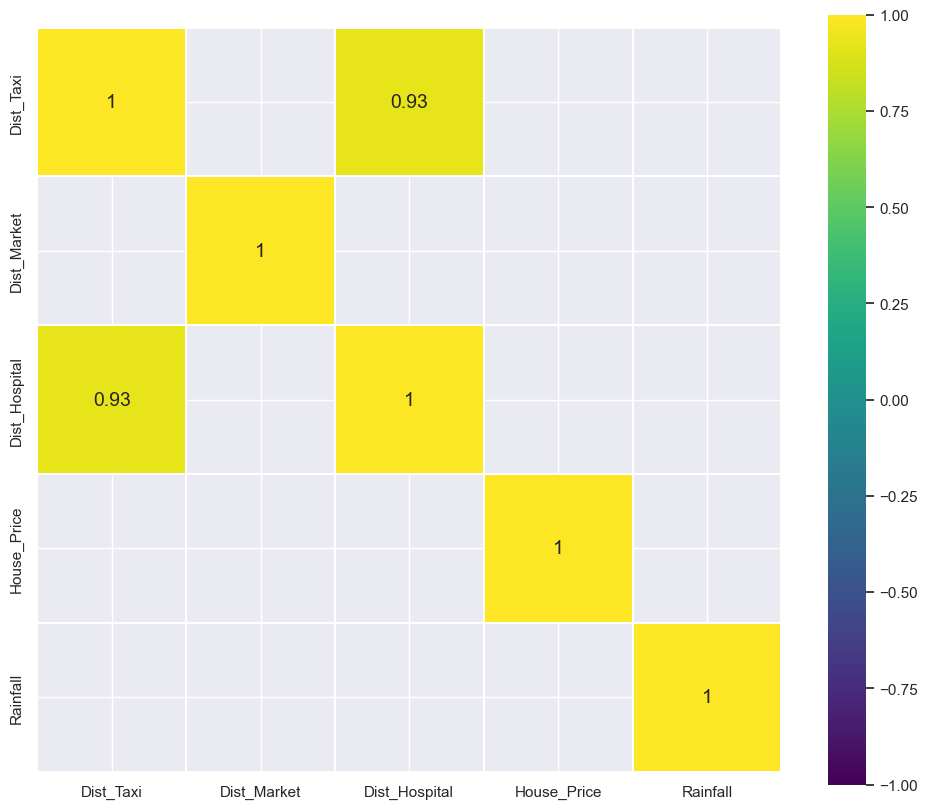

In [126]:
price2_corr = price2['Dist_Taxi Dist_Market Dist_Hospital House_Price Rainfall'.split()].corr()
corr2 = price2_corr.corr() # We already examined SalePrice correlations
plt.figure(figsize=(12, 10))
sns.heatmap(corr2[(corr2 >= 0.7) | (corr2 <= -0.7)], 
            cmap='viridis', vmax=1.0, vmin=-1.0, linewidths=0.1,
            annot=True, annot_kws={"size": 14}, square=True);

<center><h2><strong><font color="blue">End of Module</font></strong></h2></center>
<hr>
<center><img alt="" src="images/meme-cartoon/pandas-meme.jpg"/></center>
<center><img alt="" src="images/meme-cartoon/data-wrangling-meme.jpg"/></center>

# References:

1. Rattenbury, Tye, et al. Principles of data wrangling: Practical techniques for data preparation. " O'Reilly Media, Inc.", 2017.

2. McKinney, Wes. Python for data analysis: Data wrangling with Pandas, NumPy, and IPython. " O'Reilly Media, Inc.", 2012.